# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis,
**Crest** neural crest) were scored in 02 against the shared **union** control pool and
graph-smoothed. Here we render them as deliverables and evaluate **Gate 2**.

**Gate 2 (the decisive test).** Per the task spec (§1–§2), the embryonic pattern reproduces in
two forms. *Branching GO*: a Gast/pSom hub diverges into two competing arms, Crest high at the
tips. *Non-branching GO*: the programs are **present but not resolved into two arms** — Gast and
pSom co-localize as a body with **Crest as an inverse/terminal gradient**; the spec states this
"passes Gate 2 (i.e., GO), has no bifurcation for Gate 3 (i.e., NA)", and explicitly notes Gast
and pSom "may still display some cross-repression" in this case. The NO-GO is the pattern being
*absent*: no terminal Crest, modules scattered as unrelated corners (the Peng case: Crest
mid-axis, rho ~+0.1, spread triangle).

**Two reads, in order. (a) Branching test** (settles Gate 3): a fork needs cells with *both*
Gast and pSom elevated more than chance; here they occur at 0.36x with **0 forks**, so **no
bifurcation → Gate 3 = NA** — this is the non-branching case. **(b) Gate-2 read** (does the
non-branching pattern appear?): **yes** — the programs are present and organized as a Gast/pSom
body with **Crest an inverse/terminal gradient** (pSom↔Crest = **-0.71**, Crest cleanly terminal
at crest-high decile pt **0.94**, rho **+0.55**), the exact §1 non-branching signature. So
**Gate 2 = GO (non-branching)**, **Gate 3 = NA**.

**Atypical feature, flagged (spec-permitted, not disqualifying).** The canonical non-branching
case has Gast/pSom *overlapping*; here they **cross-repress** (smoothed r **-0.47**, joint-high
obs/exp **0.36**) — the spec now explicitly allows "some cross-repression" in the non-branching
case, and the repulsion is **organized**: it sits at the body end *opposite* the terminal Crest
(module-high centroids collinear, area/perim² = 0.01, Gast-high pt 0.34 → pSom-high pt 0.46 body
→ Crest-high pt 0.94 terminus), not the disorganized spread of a NO-GO. It is atypical vs the
prior GO cases (which co-varied +0.24…+0.49) because Gast is the weakest module (μ -0.025), offset
to the extreme root; both modules still decay toward the Crest terminus (rho -0.37 / -0.22), so
the body→terminal-Crest axis is intact. The axis is cell-cycle-independent (pt↔cyc rho +0.00),
so it is developmental signal, not proliferation. Deliverable: `signatures.h5ad`,
the internal Gast/pSom sign is inverted. Deliverable: `signatures.h5ad`,
`{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
CITE = 'Wu et al., 2021'

### Load the rooted manifold (signatures scored + smoothed in 02)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 24489 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 78/81 genes present
pSom: 95/98 genes present
Crest: 103/104 genes present


### Gate 2/3 - branching test, then the non-branching Gate-2 read
Reads: (i) smoothed spatial correlations; (ii) the **branching test** (settles Gate 3) - do cells
with *both* Gast and pSom elevated occur more than chance (obs/exp > 1 = fork-capable hub; < 1 =
no fork)? With the fork count this decides branching vs non-branching. (iii) module gradients
along pseudotime - the **Gate-2 read** for the non-branching case (§1): are the programs present
as a Gast/pSom body with **Crest an inverse/terminal gradient**? Supporting geometry: module-high
decile pseudotimes + centroid collinearity (area/perim²; ~0 = one organized axis, large = spread
triangle of a NO-GO). Result: no fork (obs/exp=0.36, 0 forks) → non-branching, **Gate 3 = NA**;
Crest inverse/terminal gradient present (pSom↔Crest -0.71, Crest terminal decile pt 0.94) →
**Gate 2 = GO**. Gast/pSom cross-repress (r -0.47) - spec-permitted in the non-branching case -
and the repulsion is organized (body end, opposite the terminal Crest), not disqualifying.

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')

gz = (adata.obs['Gast_sm']-adata.obs['Gast_sm'].mean())/adata.obs['Gast_sm'].std()
pz = (adata.obs['pSom_sm']-adata.obs['pSom_sm'].mean())/adata.obs['pSom_sm'].std()
hub = (gz>0.5) & (pz>0.5)
exp = ((gz>0.5).mean() * (pz>0.5).mean()) * adata.n_obs
print(f'\nHUB TEST: cells with BOTH Gast & pSom > +0.5 sd = {int(hub.sum())} ({100*hub.mean():.1f}%)')
print(f'  expected under independence = {exp:.0f} -> observed/expected = {hub.sum()/exp:.2f} (<1 = mutual exclusion, no hub)')

t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('\ngradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
# --- module-high decile pseudotimes (body modules low pt, Crest terminal) ---
for m in ['Gast_sm','pSom_sm']:
    hh = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print(f'{m} high-decile mean pt = {tn[hh.values].mean():.2f}')
# --- non-branching AXIS test: collinear body->terminal-Crest axis vs spread triangle ---
xy = adata.obsm['X_umap_lin']; cent = {}
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    hh = (adata.obs[m] >= adata.obs[m].quantile(0.9)).values; cent[m] = xy[hh].mean(0)
G,P,Cc = cent['Gast_sm'], cent['pSom_sm'], cent['Crest_sm']
area = 0.5*abs((P[0]-G[0])*(Cc[1]-G[1])-(Cc[0]-G[0])*(P[1]-G[1]))
perim = np.linalg.norm(P-G)+np.linalg.norm(Cc-P)+np.linalg.norm(G-Cc)
col = area/perim**2
print(f'\nGEOMETRY (supporting): module-high centroids area/perim^2 = {col:.3f} (~0 = one organized body->terminal-Crest axis; large = spread triangle of a NO-GO)')
rho_cyc,_ = spearmanr(t, adata.obs['cyc_score'])
print(f'pseudotime vs cell cycle rho = {rho_cyc:+.3f} (near 0 -> axis is developmental, not proliferation)')
print('\nGate 2: non-branching pattern PRESENT -> GO. Programs organized as a Gast/pSom body with Crest an inverse/terminal gradient (pSom<->Crest -0.71, Crest terminal decile pt0.94, rho+0.55) - the spec non-branching signature. Gast/pSom cross-repress (obs/exp %.2f, r-0.47), spec-permitted in the non-branching case; the repulsion is organized (body end opposite the terminal Crest, centroids collinear %.3f), flagged atypical not disqualifying.' % (hub.sum()/exp, col))
print('Gate 3: no bifurcation -> NA')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.47
  Crest_sm vs Gast_sm: r = +0.03
  Crest_sm vs pSom_sm: r = -0.71

HUB TEST: cells with BOTH Gast & pSom > +0.5 sd = 863 (3.5%)
  expected under independence = 2396 -> observed/expected = 0.36 (<1 = mutual exclusion, no hub)

gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.372
  pSom_sm: rho = -0.224
  Crest_sm: rho = +0.555
Neural-crest-high decile mean pseudotime = 0.94
Gast_sm high-decile mean pt = 0.34
pSom_sm high-decile mean pt = 0.46

GEOMETRY (supporting): module-high centroids area/perim^2 = 0.010 (~0 = one organized body->terminal-Crest axis; large = spread triangle of a NO-GO)
pseudotime vs cell cycle rho = +0.004 (near 0 -> axis is developmental, not proliferation)

Gate 2: non-branching pattern PRESENT -> GO. Programs organized as a Gast/pSom body with Crest an inverse/terminal gradient (pSom<->Crest -0.71, Crest terminal decile pt0.94, rho+0.55) - the spec non-branching si

### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left->right, `size=15` (density-matched at 24k
cells), plasma, **raw** (not smoothed) score per cell so 10x dropout is visible. The maps
show the pSom body -> Crest terminal gradient that organizes the axis; Gast is the weakest module and repels pSom, but both sit at the body end opposite the Crest terminus.

<cell 5>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar (raw range -0.19..0.16)
<cell 5>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar (raw range -0.14..0.22)
<cell 5>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar (raw range -0.19..0.14)


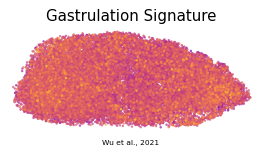

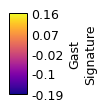

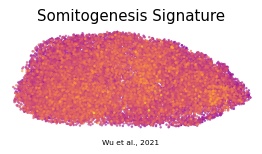

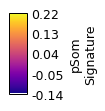

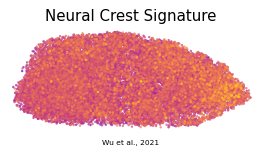

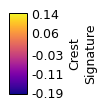

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=15, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12, CITE, ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar (raw range %.2f..%.2f)' % (lo,hi))

### Save signatures data

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (24489, 25314)
